<a href="https://colab.research.google.com/github/Zafeerxyz/Machine-Learning-algorithms/blob/main/timeSeries.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

df = pd.DataFrame({
    "date": [
        "2026-01-03",
        "2026-01-01",
        "2026-01-04",
        "2026-01-02"
    ],
    "orders": [130, 100, 145, 115]
})

print(df.head())
print(df.info())


         date  orders
0  2026-01-03     130
1  2026-01-01     100
2  2026-01-04     145
3  2026-01-02     115
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    4 non-null      object
 1   orders  4 non-null      int64 
dtypes: int64(1), object(1)
memory usage: 196.0+ bytes
None


In [2]:
df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date").reset_index(drop=True)

print(df)

        date  orders
0 2026-01-01     100
1 2026-01-02     115
2 2026-01-03     130
3 2026-01-04     145


In [3]:
df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date").reset_index(drop=True)

print(df)

        date  orders
0 2026-01-01     100
1 2026-01-02     115
2 2026-01-03     130
3 2026-01-04     145


In [4]:
# Duplicate timestamps
print("Duplicate dates:", df["date"].duplicated().sum())

# Missing values in existing rows
print(df.isna().sum())

# Set date as the index
df = df.set_index("date")

Duplicate dates: 0
date      0
orders    0
dtype: int64


In [5]:
expected_dates = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="D"
)

missing_dates = expected_dates.difference(df.index)

print("Missing dates:", missing_dates)

Missing dates: DatetimeIndex([], dtype='datetime64[ns]', freq='D')


In [6]:
df = df.reindex(expected_dates)
df.index.name = "date"

print(df)

            orders
date              
2026-01-01     100
2026-01-02     115
2026-01-03     130
2026-01-04     145


In [7]:
df["orders"] = df["orders"].fillna(0)

In [8]:
import matplotlib.pyplot as plt

from statsmodels.datasets import co2

data = co2.load_pandas().data

series = data["co2"].resample("MS").mean()
series = series.interpolate(method ="time")

print(series.head())
print(series.isna().sum())

1958-03-01    316.100000
1958-04-01    317.200000
1958-05-01    317.433333
1958-06-01    316.514344
1958-07-01    315.625000
Freq: MS, Name: co2, dtype: float64
0


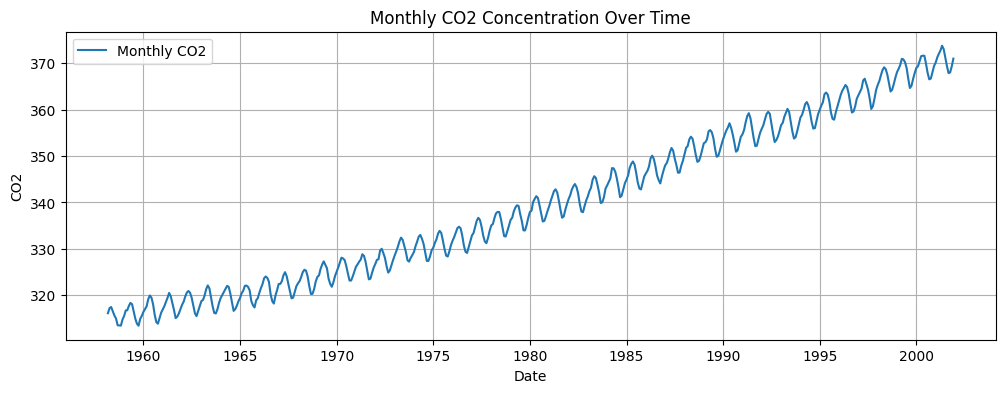

In [9]:
plt.figure(figsize=(12, 4))

plt.plot(series.index, series, label="Monthly CO2")
plt.title("Monthly CO2 Concentration Over Time")
plt.xlabel("Date")
plt.ylabel("CO2")
plt.legend()
plt.grid(True)
plt.show()

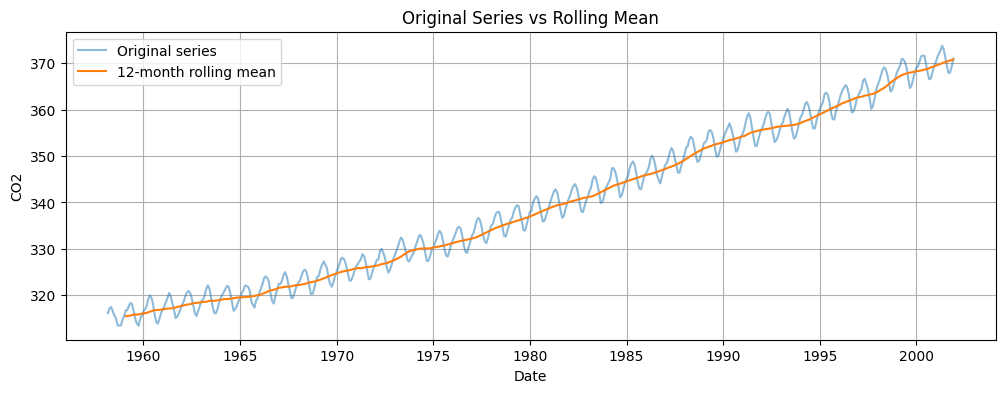

In [10]:
rolling_mean = series.rolling(window=12).mean()

plt.figure(figsize=(12, 4))

plt.plot(series.index, series, label="Original series", alpha=0.5)
plt.plot(rolling_mean.index, rolling_mean,
         label="12-month rolling mean")

plt.title("Original Series vs Rolling Mean")
plt.xlabel("Date")
plt.ylabel("CO2")
plt.legend()
plt.grid(True)
plt.show()

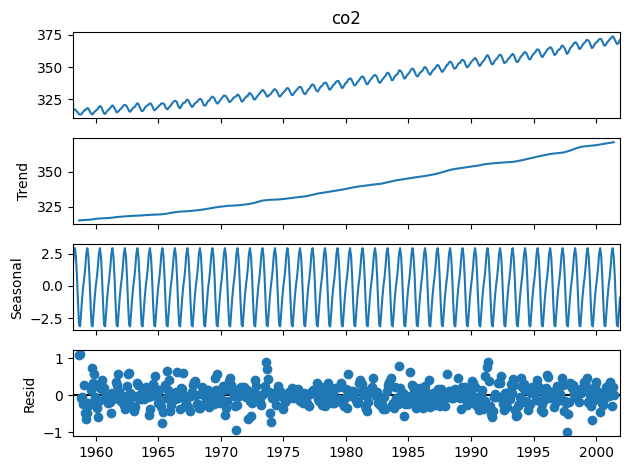

In [11]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    series,
    model="additive",
    period=12
)

decomposition.plot()
plt.tight_layout()
plt.show()

In [12]:


split_point = int(len(series) * 0.8)

train = series.iloc[:split_point]
test = series.iloc[split_point:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Training ends:", train.index.max())
print("Testing starts:", test.index.min())

Training observations: 420
Testing observations: 106
Training ends: 1993-02-01 00:00:00
Testing starts: 1993-03-01 00:00:00


In [13]:
naive_forecast = pd.Series(
    train.iloc[-1],
    index=test.index,
    name="Naive Forecast"
)

In [14]:
last_12_months_mean = train.tail(12).mean()

moving_avg_forecast = pd.Series(
    last_12_months_mean,
    index=test.index,
    name="Moving Average Forecast"
)

print("Naive forecast value:", train.iloc[-1])
print("Moving-average forecast value:", last_12_months_mean)

Naive forecast value: 357.175
Moving-average forecast value: 356.44583333333327


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def evaluate_forecast(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }

results = pd.DataFrame({
    "Naive": evaluate_forecast(test, naive_forecast),
    "Moving Average": evaluate_forecast(test, moving_avg_forecast)
}).T

print(results.round(3))

                  MAE   RMSE  MAPE (%)
Naive           7.434  8.687     2.025
Moving Average  8.073  9.299     2.199


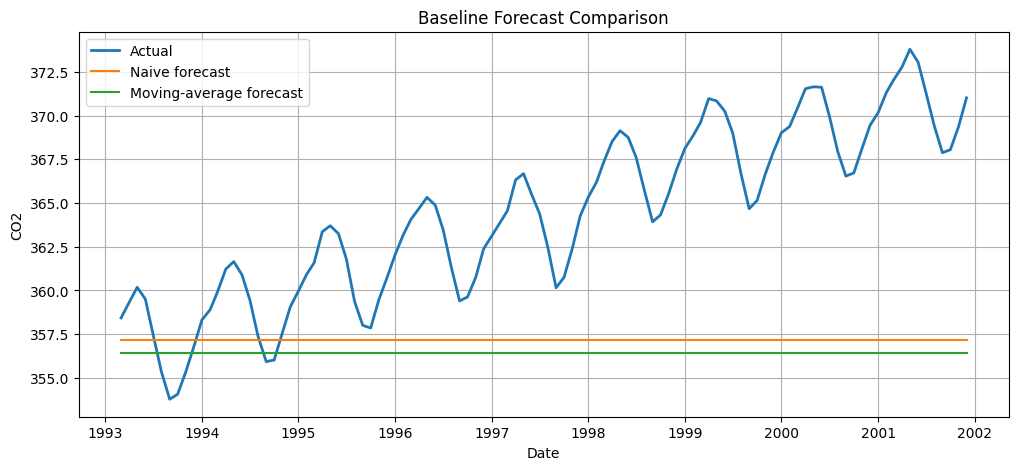

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(test.index, test, label="Actual", linewidth=2)
plt.plot(test.index, naive_forecast, label="Naive forecast")
plt.plot(test.index, moving_avg_forecast, label="Moving-average forecast")

plt.title("Baseline Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("CO2")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
import numpy as np
import pandas as pd

seasonal_values = train.tail(12).to_numpy()

seasonal_forecast = pd.Series(
    np.tile(
        seasonal_values,
        int(np.ceil(len(test) / 12))
    )[:len(test)],
    index=test.index,
    name="Seasonal Naive"
)

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def evaluate_forecast(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }

forecasts = {
    "Naive": naive_forecast,
    "Moving Average": moving_avg_forecast,
    "Seasonal Naive": seasonal_forecast
}

results = pd.DataFrame({
    name: evaluate_forecast(test, prediction)
    for name, prediction in forecasts.items()
}).T

print(results.round(3))

                  MAE   RMSE  MAPE (%)
Naive           7.434  8.687     2.025
Moving Average  8.073  9.299     2.199
Seasonal Naive  7.927  9.126     2.161


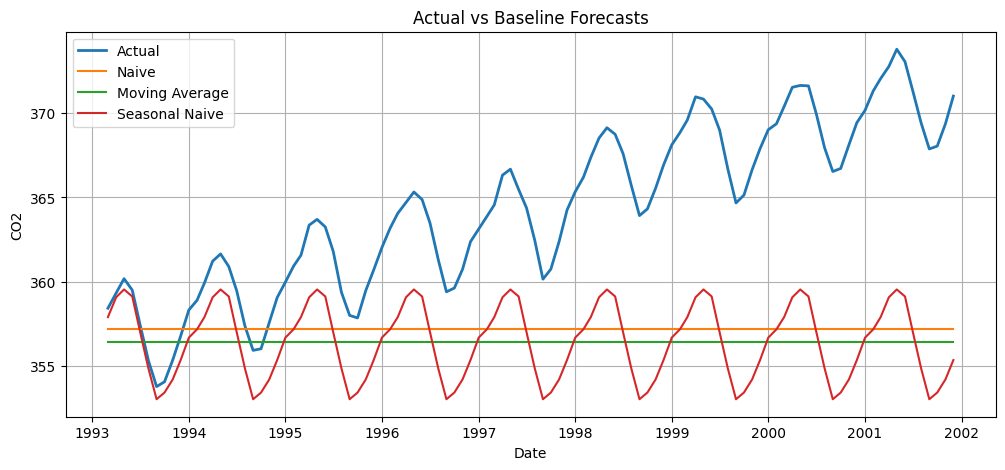

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(test.index, test, label="Actual", linewidth=2)

for name, prediction in forecasts.items():
    plt.plot(prediction.index, prediction, label=name)

plt.title("Actual vs Baseline Forecasts")
plt.xlabel("Date")
plt.ylabel("CO2")
plt.legend()
plt.grid(True)
plt.show()